In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/shai-music-genre-classification/test (2).csv
/kaggle/input/competitions/shai-music-genre-classification/sample_submission (2).csv
/kaggle/input/competitions/shai-music-genre-classification/train (1).csv


In [2]:
import os

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        if filename.endswith(".csv"):
            print(os.path.join(dirname, filename))

/kaggle/input/competitions/shai-music-genre-classification/test (2).csv
/kaggle/input/competitions/shai-music-genre-classification/sample_submission (2).csv
/kaggle/input/competitions/shai-music-genre-classification/train (1).csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thư mục chứa dữ liệu
data_path = "/kaggle/input/competitions/shai-music-genre-classification/"

# Đọc ba file
train = pd.read_csv(data_path + "train (1).csv")
test = pd.read_csv(data_path + "test (2).csv")
sample_submission = pd.read_csv(data_path + "sample_submission (2).csv")

# Kiểm tra kích thước
print("Train:", train.shape)
print("Test:", test.shape)
print("Submission:", sample_submission.shape)

# Xem 5 dòng đầu tiên
train.head()

Train: (14396, 18)
Test: (3600, 17)
Submission: (3600, 2)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14396 entries, 0 to 14395
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Id                  14396 non-null  int64  
 1   Artist Name         14396 non-null  object 
 2   Track Name          14396 non-null  object 
 3   Popularity          14063 non-null  float64
 4   danceability        14396 non-null  float64
 5   energy              14396 non-null  float64
 6   key                 12787 non-null  float64
 7   loudness            14396 non-null  float64
 8   mode                14396 non-null  int64  
 9   speechiness         14396 non-null  float64
 10  acousticness        14396 non-null  float64
 11  instrumentalness    10855 non-null  float64
 12  liveness            14396 non-null  float64
 13  valence             14396 non-null  float64
 14  tempo               14396 non-null  float64
 15  duration_in min/ms  14396 non-null  float64
 16  time

#### Thống kê dữ liệu thiếu

In [5]:
missing = pd.DataFrame({
    "So luong thieu": train.isna().sum(),
    "Ty le thieu (%)": train.isna().mean() * 100
})

missing = missing[missing["So luong thieu"] > 0]
missing.sort_values("So luong thieu", ascending=False).round(2)

,So luong thieu,Ty le thieu (%)
instrumentalness,3541,24.60
key,1609,11.18
Popularity,333,2.31


       So luong  Ty le (%)
Class                     
0           500       3.47
1          1098       7.63
2          1018       7.07
3           322       2.24
4           310       2.15
5          1157       8.04
6          2069      14.37
7           461       3.20
8          1483      10.30
9          2019      14.02
10         3959      27.50


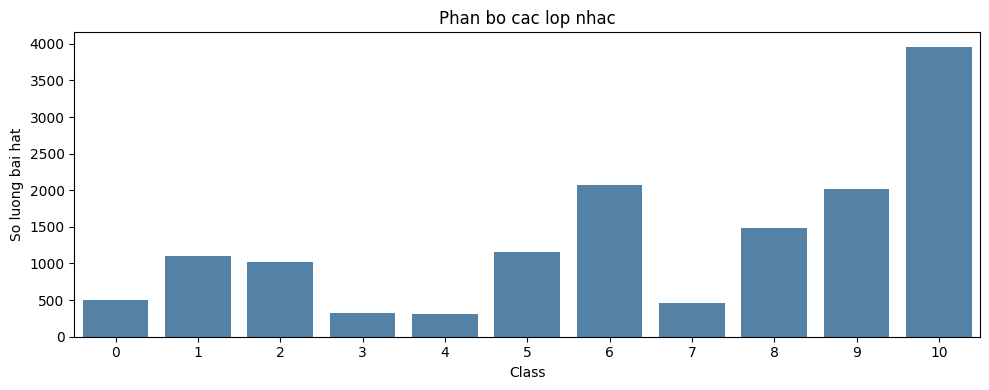

In [6]:
class_summary = pd.DataFrame({
    "So luong": train["Class"].value_counts().sort_index(),
    "Ty le (%)": train["Class"].value_counts(
        normalize=True
    ).sort_index() * 100
})

print(class_summary.round(2))

plt.figure(figsize=(10, 4))
sns.countplot(data=train, x="Class", color="steelblue")
plt.title("Phan bo cac lop nhac")
plt.xlabel("Class")
plt.ylabel("So luong bai hat")
plt.tight_layout()
plt.show()

In [7]:
print("So dong trung hoan toan:", train.duplicated().sum())

print(
    "So dong lap theo nghe si va ten bai:",
    train.duplicated(
        subset=["Artist Name", "Track Name"]
    ).sum()
)

So dong trung hoan toan: 0
So dong lap theo nghe si va ten bai: 1220


In [8]:
print("DU LIEU THIEU:")
print(train.isna().sum()[train.isna().sum() > 0])

print("\nTRUNG TOAN BO DONG:")
print(train.duplicated().sum())

print("\nTRUNG NGHE SI VA TEN BAI:")
print(train.duplicated(subset=["Artist Name", "Track Name"]).sum())

DU LIEU THIEU:
Popularity           333
key                 1609
instrumentalness    3541
dtype: int64

TRUNG TOAN BO DONG:
0

TRUNG NGHE SI VA TEN BAI:
1220


In [9]:
song_cols = ["Artist Name", "Track Name"]

# keep=False: lấy tất cả các dòng thuộc nhóm bài trùng
duplicate_songs = train[
    train.duplicated(subset=song_cols, keep=False)
]

print("Tong so dong thuoc cac nhom trung:", len(duplicate_songs))

duplicate_songs.sort_values(song_cols).head(20)

Tong so dong thuoc cac nhom trung: 2323


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
382,383,'68,Bad Bite,36.0,0.558,0.977,1.0,-5.082,1,0.2110,0.000618,0.001300,0.3160,0.473,167.984,190031.000000,4,1
6235,6236,'68,Bad Bite,36.0,0.558,0.977,1.0,-5.082,1,0.2110,0.000618,0.001300,0.3160,0.473,167.984,190031.000000,4,6
8214,8215,'68,Bad Bite,36.0,0.558,0.977,1.0,-5.082,1,0.2110,0.000618,0.001300,0.3160,0.473,167.984,190031.000000,4,10
6408,6409,100 gecs,money machine,70.0,0.680,0.659,6.0,-7.186,1,0.1510,0.229000,NaN,0.4740,0.750,98.877,114460.000000,4,9
10871,10872,100 gecs,money machine,70.0,0.680,0.659,6.0,-7.186,1,0.1510,0.229000,NaN,0.4740,0.750,98.877,114460.000000,4,6
6343,6344,1000mods,Mirrors,35.0,0.333,0.820,5.0,-7.361,1,0.0531,0.000288,0.264000,0.0891,0.162,115.120,436333.000000,4,8
8186,8187,1000mods,Mirrors,35.0,0.333,0.820,5.0,-7.361,1,0.0531,0.000288,0.264000,0.0891,0.162,115.120,436333.000000,4,10
7922,7923,13th Floor Elevators,Slip Inside This House - Stereo LP Version,43.0,0.555,0.694,9.0,-8.453,0,0.0426,0.101000,NaN,0.1230,0.602,127.423,482278.000000,4,10
8414,8415,13th Floor Elevators,Slip Inside This House - Stereo LP Version,43.0,0.555,0.694,9.0,-8.453,0,0.0426,0.101000,NaN,0.1230,0.602,127.423,482278.000000,4,2
5810,5811,347aidan,Dancing in My Room,3.0,0.979,0.410,8.0,-11.056,0,0.1120,0.658000,0.000034,0.2050,0.740,119.971,3.002033,4,9


In [10]:
# Đếm số nhãn khác nhau của mỗi bài
labels_per_song = train.groupby(song_cols)["Class"].nunique()

conflicting_songs = labels_per_song[labels_per_song > 1]

print("So nhom bai hat co nhieu nhan:", len(conflicting_songs))
print(conflicting_songs.head(10))

So nhom bai hat co nhieu nhan: 1043
Artist Name           Track Name                                
'68                   Bad Bite                                      3
100 gecs              money machine                                 2
1000mods              Mirrors                                       2
13th Floor Elevators  Slip Inside This House - Stereo LP Version    2
347aidan              Dancing in My Room                            2
4 Non Blondes         What's Up?                                    2
? & The Mysterians    96 Tears                                      2
A Perfect Circle      The Doomed                                    2
AC/DC                 Back In Black                                 2
                      Highway to Hell                               2
Name: Class, dtype: int64


In [11]:
train.drop(columns=["Id", "Class"]).describe().T

,count,mean,std,min,25%,50%,75%,max
Popularity,14063.0,44.525208,17.418940,1.000000,33.000000,44.00000,56.00000,100.000
danceability,14396.0,0.543105,0.165517,0.059600,0.432000,0.54500,0.65800,0.989
energy,14396.0,0.662422,0.235967,0.001210,0.508000,0.69900,0.86100,1.000
key,12787.0,5.953781,3.200013,1.000000,3.000000,6.00000,9.00000,11.000
loudness,14396.0,-7.900852,4.057362,-39.952000,-9.538000,-7.01350,-5.16200,1.342
mode,14396.0,0.640247,0.479944,0.000000,0.000000,1.00000,1.00000,1.000
speechiness,14396.0,0.080181,0.085157,0.022500,0.034800,0.04710,0.08310,0.955
acousticness,14396.0,0.246746,0.310922,0.000000,0.004280,0.08145,0.43225,0.996
instrumentalness,10855.0,0.178129,0.304266,0.000001,0.000088,0.00392,0.20100,0.996
liveness,14396.0,0.195782,0.159258,0.011900,0.097275,0.12900,0.25600,0.992


In [12]:
# Chuẩn hóa tên để nhận diện cùng bài hát
song_info = train[["Artist Name", "Track Name"]].fillna("")

song_info = song_info.apply(
    lambda col: col.str.strip().str.lower()
)

# Mỗi cặp nghệ sĩ + tên bài có một mã nhóm
song_groups = song_info.groupby(
    ["Artist Name", "Track Name"]
).ngroup()

print("So nhom bai hat:", song_groups.nunique())

So nhom bai hat: 13166


In [13]:
from sklearn.model_selection import StratifiedGroupKFold

# V1 dùng các đặc trưng số
X = train.drop(columns=["Id", "Artist Name", "Track Name", "Class"])
y = train["Class"]

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Lấy một fold làm validation
train_idx, valid_idx = next(
    splitter.split(X, y, groups=song_groups)
)

X_train = X.iloc[train_idx].copy()
X_valid = X.iloc[valid_idx].copy()

y_train = y.iloc[train_idx].copy()
y_valid = y.iloc[valid_idx].copy()

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (11536, 14)
X_valid: (2860, 14)
y_train: (11536,)
y_valid: (2860,)


In [14]:
train_groups = set(song_groups.iloc[train_idx])
valid_groups = set(song_groups.iloc[valid_idx])

print("So nhom trung giua hai tap:",
      len(train_groups.intersection(valid_groups)))

class_ratio = pd.DataFrame({
    "Train (%)": y_train.value_counts(normalize=True) * 100,
    "Valid (%)": y_valid.value_counts(normalize=True) * 100
}).sort_index()

print(class_ratio.round(2))

So nhom trung giua hai tap: 0
       Train (%)  Valid (%)
Class                      
0           3.48       3.46
1           7.53       8.01
2           7.02       7.27
3           2.25       2.17
4           2.10       2.38
5           7.97       8.32
6          14.25      14.86
7           3.18       3.29
8          10.38       9.97
9          14.03      14.02
10         27.81      26.26


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

model_v1 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Huấn luyện trên tập train đã chia
model_v1.fit(X_train, y_train)

# Giữ đúng các cột và thứ tự đặc trưng
X_test = test[X_train.columns]

test_predictions = model_v1.predict(X_test)

In [16]:
submission = pd.DataFrame({
    "Id": test["Id"],
    "Class": test_predictions
})

submission.to_csv("/kaggle/working/submission.csv", index=False)

print(submission.shape)
submission.head()

(3600, 2)


,Id,Class
0,14397,6
1,14398,6
2,14399,9
3,14400,10
4,14401,5


In [17]:
from sklearn.metrics import accuracy_score, f1_score

pred_train_v1 = model_v1.predict(X_train)
pred_valid_v1 = model_v1.predict(X_valid)

print("V1 Train Accuracy:",
      accuracy_score(y_train, pred_train_v1))
print("V1 Valid Accuracy:",
      accuracy_score(y_valid, pred_valid_v1))
print("V1 Valid Macro F1:",
      f1_score(y_valid, pred_valid_v1, average="macro"))

V1 Train Accuracy: 0.9218099861303745
V1 Valid Accuracy: 0.5548951048951049
V1 Valid Macro F1: 0.5884906132003637


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesClassifier

model_v2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", ExtraTreesClassifier(
        n_estimators=400,
        random_state=42,
        n_jobs=-1
    ))
])

model_v2.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 ExtraTreesClassifier(n_estimators=400, n_jobs=-1,
                                      random_state=42))])

In [19]:
pred_train_v2 = model_v2.predict(X_train)
pred_valid_v2 = model_v2.predict(X_valid)

comparison = pd.DataFrame({
    "Model": ["V1 - Random Forest", "V2 - Extra Trees"],
    "Train Accuracy": [
        accuracy_score(y_train, pred_train_v1),
        accuracy_score(y_train, pred_train_v2)
    ],
    "Valid Accuracy": [
        accuracy_score(y_valid, pred_valid_v1),
        accuracy_score(y_valid, pred_valid_v2)
    ],
    "Valid Macro F1": [
        f1_score(y_valid, pred_valid_v1, average="macro"),
        f1_score(y_valid, pred_valid_v2, average="macro")
    ]
})

print(comparison.round(4).to_string(index=False))

             Model  Train Accuracy  Valid Accuracy  Valid Macro F1
V1 - Random Forest          0.9218          0.5549          0.5885
  V2 - Extra Trees          0.9218          0.5437          0.5689


In [20]:
print(comparison.round(4).to_string(index=False))

             Model  Train Accuracy  Valid Accuracy  Valid Macro F1
V1 - Random Forest          0.9218          0.5549          0.5885
  V2 - Extra Trees          0.9218          0.5437          0.5689


In [21]:
from sklearn.metrics import classification_report

# Kết quả từng lớp của mô hình tốt nhất hiện tại
print("BAO CAO V1:")
print(classification_report(
    y_valid,
    pred_valid_v1,
    digits=4,
    zero_division=0
))

# Kiểm tra các dòng có cùng đặc trưng số nhưng khác nhãn
feature_cols = X.columns.tolist()

labels_per_features = train.groupby(
    feature_cols,
    dropna=False
)["Class"].nunique()

print(
    "So nhom dac trung giong nhau nhung khac nhan:",
    (labels_per_features > 1).sum()
)

BAO CAO V1:
              precision    recall  f1-score   support

           0     0.7434    0.8485    0.7925        99
           1     0.5000    0.0175    0.0338       229
           2     0.6549    0.3558    0.4611       208
           3     0.8214    0.7419    0.7797        62
           4     0.6769    0.6471    0.6617        68
           5     0.6549    0.7017    0.6775       238
           6     0.4416    0.3200    0.3711       425
           7     0.9778    0.9362    0.9565        94
           8     0.6274    0.5789    0.6022       285
           9     0.5682    0.5711    0.5697       401
          10     0.4637    0.7324    0.5679       751

    accuracy                         0.5549      2860
   macro avg     0.6482    0.5864    0.5885      2860
weighted avg     0.5635    0.5549    0.5283      2860

So nhom dac trung giong nhau nhung khac nhan: 994


In [22]:
from sklearn.base import clone

# Tạo mô hình riêng để huấn luyện trên toàn bộ dữ liệu
# Giữ model_v1 ban đầu để bảo toàn kết quả validation
final_model = clone(model_v1)

X_full = train[X_train.columns]
y_full = train["Class"]

final_model.fit(X_full, y_full)

# Dự đoán tập test
test_predictions = final_model.predict(test[X_train.columns])

# Tạo file đúng định dạng
submission = pd.DataFrame({
    "Id": test["Id"],
    "Class": test_predictions.astype(int)
})

submission.to_csv("/kaggle/working/submission.csv", index=False)

print("Da tao submission.csv")
print("Kich thuoc:", submission.shape)
print(submission.head())

Da tao submission.csv
Kich thuoc: (3600, 2)
      Id  Class
0  14397      6
1  14398      6
2  14399      9
3  14400     10
4  14401      5
